# GWR Results Visualisation

This notebook turns local GWR/GWNBR outputs into maps and diagnostic figures. It combines per-edge coefficients and standard errors with global model summaries, using the model's projected geometry for spatial display.

In [28]:
# Plotting and model-result imports.
import rdata
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


In [29]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm
from scipy.spatial import cKDTree

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['axes.formatter.useoffset'] = False
plt.rcParams['axes.formatter.limits'] = (-100, 100)

In [30]:
def save_current_plot_svg(filename="current_plot.svg", fig=None):
    """Save a Matplotlib figure as SVG and print the output path."""
    if fig is None:
        fig = plt.gcf()
    path = f"Plots\Final_Report_Figs\{filename}"
    fig.savefig(path, format="svg", bbox_inches="tight")
    print(f"Saved SVG plot to: {path}")
    return path

<string>:5: SyntaxWarning: invalid escape sequence '\{'
<>:5: SyntaxWarning: invalid escape sequence '\{'
<>:5: SyntaxWarning: invalid escape sequence '\F'
<string>:5: SyntaxWarning: invalid escape sequence '\{'
<>:5: SyntaxWarning: invalid escape sequence '\{'
<>:5: SyntaxWarning: invalid escape sequence '\F'
C:\Users\maxwe\AppData\Local\Temp\ipykernel_32556\2853579358.py:5: SyntaxWarning: invalid escape sequence '\{'
  path = f"Plots\Final_Report_Figs\{filename}"
C:\Users\maxwe\AppData\Local\Temp\ipykernel_32556\2853579358.py:5: SyntaxWarning: invalid escape sequence '\F'
  path = f"Plots\Final_Report_Figs\{filename}"


## 1. Configuration

Set the input paths and plotting options before running the visualisation cells. `GPKG_PATH` contains local parameter estimates and geometries; the R data files contain fitted-model diagnostics and global comparison results. `EXCLUDE_FROM_COEF_PLOTS` prevents intercept or dispersion parameters from being mapped as spatial covariates.

In [31]:
pick = "bike"
match pick:
    case "bike":
        GPKG_PATH = r"GWNBR_Output\Bike_Results\bike_gwnbr_results.gpkg"       # Local geometries and coefficient estimates.
        RESULTS_PATH = r"GWNBR_Output\Bike_Results\bike_gwnbr_full_result.rds"    # Local diagnostics, bandwidth, and effective parameters.
        GLOBAL_RESULTS_PATH = r"GWNBR_Output\glm_nb_results.RData"  # Global negative-binomial coefficients and diagnostics.
        FORWARD_SELECTION_PATH = r"GWNBR_Output\Bike_Results\fvs_bike.csv"
    case "ped":
        GPKG_PATH = r"GWNBR_Output\Ped_Results\ped_gwnbr_results.gpkg"       # Local geometries and coefficient estimates.
        RESULTS_PATH = r"GWNBR_Output\Ped_Results\ped_gwnbr_full_result.rds"    # Local diagnostics, bandwidth, and effective parameters.
        GLOBAL_RESULTS_PATH = r"GWNBR_Output\glm_nb_results.RData"  # Global negative-binomial coefficients and diagnostics.
        FORWARD_SELECTION_PATH = r"GWNBR_Output\Ped_Results\fvs_ped.csv"
BORDER_PATH = r"Data\lds-nz-coastlines-topo-150k-SHP\nz-coastlines-topo-150k.shp"      # Coastline/border overlay.
# Exclude intercept or dispersion terms from spatial coefficient maps.
EXCLUDE_FROM_COEF_PLOTS = ["b_alpha","b_Intercept"]


## 2. Load model outputs

Load the local result geometries, the study-area border, and the serialized local and global model objects. The border is reprojected to the same CRS as the result layer so it overlays correctly.

In [32]:
gdf = gpd.read_file(GPKG_PATH)
border = gpd.read_file(BORDER_PATH).to_crs(gdf.crs)


def plot_border_under(ax):
    border.plot(ax=ax, color="black", linewidth=1.5, zorder=1)


def zoom_to_data(ax, padding=0.2):
    min_x, min_y, max_x, max_y = gdf.total_bounds
    width = max_x - min_x
    height = max_y - min_y
    ax.set_xlim(min_x - padding * width, max_x + padding * width)
    ax.set_ylim(min_y - padding * height, max_y + padding * height)


print(f"Loaded {len(gdf)} rows, CRS: {gdf.crs}")
print(f"Loaded area border with {len(border)} feature(s)")
gdf.head()


Loaded 3126 rows, CRS: EPSG:2193
Loaded area border with 2 feature(s)


c:\Users\maxwe\anaconda3\envs\geospatial_study\Lib\site-packages\pyogrio\raw.py:198: RuntimeWarning: This version of GeoPackage user_version=0x000028A0 (10400, v1.4.0) on 'GWNBR_Output\Bike_Results\bike_gwnbr_results.gpkg' may only be partially supported
  return ogr_read(


,edgeUID,elevation_range,elevation_max,gradient,road,distance_to_road,Rural_settlement_distances,Small_urban_distances,trail_density_400m,Artificial_proportion,...,Y,yhat,res,b_Intercept,b_trail_density_400m,b_alpha,se_Intercept,se_trail_density_400m,se_alpha,geometry
0,40157914,14.480400,62.909615,0.049561,False,1069.255483,1069.255483,1069.255483,0.011506,0.0,...,1140.0,2879.107471,-1739.107471,7.927407,3.287625,0.896274,2.288522,155.153806,0.420414,"LINESTRING (1566602.329 5172833.423, 1566586.0..."
1,40158140,0.803947,40.802662,0.016288,False,1169.354950,1169.354950,1169.354950,0.015113,0.0,...,430.0,2973.220502,-2543.220502,11.661350,-242.437576,1.224822,3.195866,217.035744,0.345979,"LINESTRING (1566455.64 5172648.094, 1566461.29..."
2,40158153,0.056458,40.673653,0.004056,False,1191.874433,1191.874433,1191.874433,0.015940,0.0,...,125.0,1827.799670,-1702.799670,8.538279,-64.455743,1.336279,1.256706,83.892634,0.494402,"LINESTRING (1566556.846 5172732.852, 1566543.2..."
3,40158170,4.910843,79.592880,0.117539,False,767.982631,767.982631,767.982631,0.020501,0.0,...,1395.0,2770.011906,-1375.011906,8.063579,-6.681340,0.617950,1.279241,82.011185,0.169076,"LINESTRING (1566745.34 5172655.19, 1566740.152..."
4,40158183,6.886086,88.735352,0.117780,False,686.172468,686.172468,686.172468,0.022232,0.0,...,1905.0,2015.751280,-110.751280,9.772629,-97.330107,0.294390,1.433354,91.310496,0.102724,"LINESTRING (1566753.954 5172636.918, 1566756.2..."


In [33]:
with open(RESULTS_PATH, "rb") as f:
    parsed_data = rdata.parser.parse_file(RESULTS_PATH)
    results = rdata.conversion.convert(parsed_data)

print("Top-level keys in results object:")
try:
    print(list(results.keys()))
except AttributeError:
    print("(results is not a dict — it looks like a fitted GWRResults object; adjust access below accordingly)")

parsed_global_data = rdata.parser.parse_file(GLOBAL_RESULTS_PATH)
global_results = rdata.conversion.convert(parsed_global_data)
print("Top-level keys in global results object:")
try:
    print(list(global_results.keys()))
except AttributeError:
    print(type(global_results))


Top-level keys in results object:
[np.str_('general_bandwidth'), np.str_('fitted_values'), np.str_('measures'), np.str_('ENP'), np.str_('mgwr_param_estimates'), np.str_('alpha_level_5_pct'), np.str_('t_critical'), np.str_('mgwr_se'), np.str_('global_param_estimates'), np.str_('t_test_dfs'), np.str_('global_measures')]
Top-level keys in global results object:
['coef_table', 'irr_table', 'model_stats']


c:\Users\maxwe\anaconda3\envs\geospatial_study\Lib\site-packages\rdata\conversion\_conversion.py:918: UserWarning: Missing constructor for R class "mgwnbr_model". The underlying R object is returned instead.
  warnings.warn(
c:\Users\maxwe\anaconda3\envs\geospatial_study\Lib\site-packages\rdata\conversion\_conversion.py:918: UserWarning: Missing constructor for R class "logLik". The underlying R object is returned instead.
  warnings.warn(
c:\Users\maxwe\anaconda3\envs\geospatial_study\Lib\site-packages\rdata\conversion\_conversion.py:918: UserWarning: Missing constructor for R class "tbl_df". The constructor for class "tbl" will be used instead.
  warnings.warn(
c:\Users\maxwe\anaconda3\envs\geospatial_study\Lib\site-packages\rdata\conversion\_conversion.py:918: UserWarning: Missing constructor for R class "tbl". The constructor for class "data.frame" will be used instead.
  warnings.warn(
c:\Users\maxwe\anaconda3\envs\geospatial_study\Lib\site-packages\rdata\conversion\_conversion.py

## 3. Count and study-area plots

This section is reserved for overview maps of the observed counts and the modelling area.

## 4. Forward variable selection

Read the forward-selection log and retain rows marked `SELECTED`. The resulting AIC plot shows how the model criterion changed as variables were added.

In [34]:
# Load the forward-selection history and keep the selected model steps.
fs_df = pd.read_csv(FORWARD_SELECTION_PATH)
# Filter to variables retained by the selection procedure.
selected_fs_df = fs_df[fs_df['Status_Selected'] == "SELECTED"]

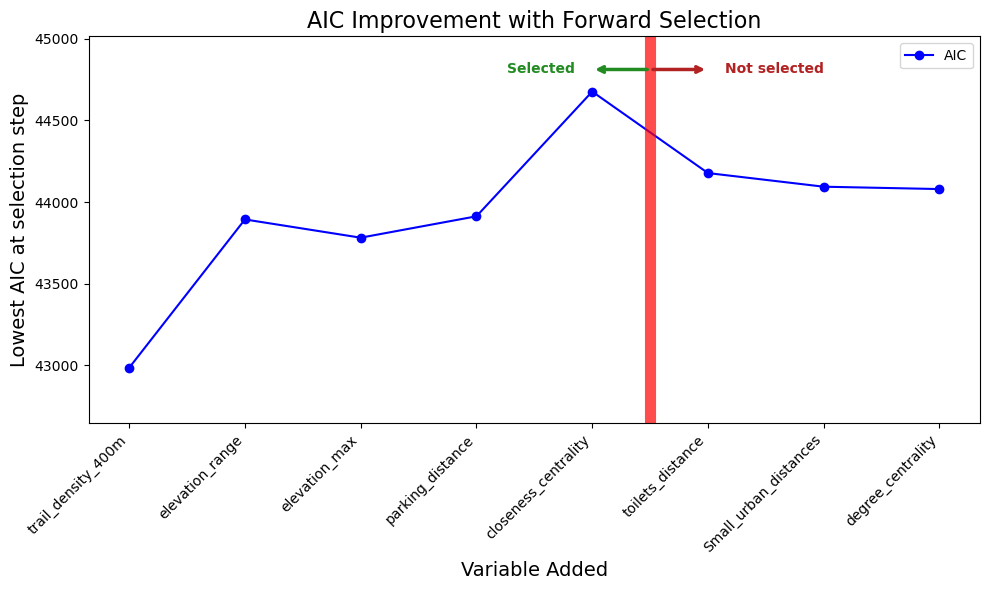

In [35]:
# Plot the AIC trajectory as variables are added.
fig, ax = plt.subplots(figsize=(10, 6), facecolor="white")
ax.plot(
    selected_fs_df["Iteration"], selected_fs_df["AIC"],
    marker="o", linestyle="-", color="blue", label="AIC"
)


# Add directional labels around the selected iteration.
y_min = selected_fs_df["AIC"].min()
y_max = selected_fs_df["AIC"].max()
y_range = max(y_max - y_min, 1)
ax.axvline(x=5.5, color="red", linestyle="-", linewidth=8, alpha=0.7)
arrow_y = y_max + 0.08 * y_range
ax.annotate(
    "", xy=(5, arrow_y), xytext=(5.5, arrow_y),
    arrowprops={"arrowstyle": "->", "color": "forestgreen", "lw": 2.5},
)
ax.text(4.85, arrow_y, "Selected", color="forestgreen", ha="right", va="center", weight="bold")
ax.annotate(
    "", xy=(6, arrow_y), xytext=(5.5, arrow_y),
    arrowprops={"arrowstyle": "->", "color": "firebrick", "lw": 2.5},
)
ax.text(6.15, arrow_y, "Not selected", color="firebrick", ha="left", va="center", weight="bold")

ax.set_ylim(y_min-0.2 * y_range, y_max + 0.2 * y_range)

ax.set_title("AIC Improvement with Forward Selection", fontsize=16)
ax.set_xlabel("Variable Added", fontsize=14)
ax.set_ylabel("Lowest AIC at selection step", fontsize=14)
ax.set_xticks(selected_fs_df["Iteration"])
ax.set_xticklabels(selected_fs_df["Tested_Variable"], rotation=45, ha="right")
ax.legend()
fig.tight_layout()
plt.show()

In [36]:
save_current_plot_svg(filename="forward_selection_aic_plot.svg", fig=fig)

Saved SVG plot to: Plots\Final_Report_Figs\forward_selection_aic_plot.svg


'Plots\\Final_Report_Figs\\forward_selection_aic_plot.svg'

## 5. Identify local parameter columns

Local coefficient columns use the `b_` prefix and their corresponding standard errors use `se_`. Pairing these columns enables coefficient maps and approximate pseudo-t statistics.

In [37]:
b_cols = [c for c in gdf.columns if c.startswith("b_")]
se_cols = [c for c in gdf.columns if c.startswith("se_")]

# Match each coefficient with its corresponding standard-error column.
param_names = [c[2:] for c in b_cols]
missing_se = [p for p in param_names if f"se_{p}" not in gdf.columns]
if missing_se:
    print("Warning — no matching se_ column for:", missing_se)

param_names = [p for p in param_names if f"b_{p}" not in EXCLUDE_FROM_COEF_PLOTS]
print(f"Found {len(param_names)} parameters:")
param_names


Found 1 parameters:


['trail_density_400m']

## 6. Configure focus areas

Focus limits are expressed as fractions of the full projected data extent. They allow the map grids to include a detailed inset-like view of selected network segments without changing the underlying geometries.

In [38]:
def focus_area_bounds(
    gdf,
    x_start=0.0,
    x_end=0.45,
    y_start=0.84,
    y_end=1.0,
    padding=0.0,
):
    """Return focus-map limits from fractional data bounds.

    Fractions are measured from the lower-left of the full dataset extent.
    Increase padding to expand the box around all selected segments.
    """
    min_x, min_y, max_x, max_y = gdf.total_bounds
    width = max_x - min_x
    height = max_y - min_y
    pad_x = padding * width
    pad_y = padding * height

    x_limits = (
        min_x + x_start * width - pad_x,
        min_x + x_end * width + pad_x,
    )
    y_limits = (
        min_y + y_start * height - pad_y,
        min_y + y_end * height + pad_y,
    )
    return x_limits, y_limits



In [39]:

# Adjust these values to move or expand the focus area around the segments.
CL_X_START = 0.0
CL_X_END = 0.45
CL_Y_START = 0.75
CL_Y_END = 1.0
CL_PADDING = 0.0

TAP_X_START = 0.09
TAP_X_END = 0.6
TAP_Y_START = 0.45
TAP_Y_END = 0.75
TAP_PADDING = 0.0

AKA_X_START = 0.7
AKA_X_END = 0.95
AKA_Y_START = 0.12
AKA_Y_END = 0.35
AKA_PADDING = 0.0


## 7. Local parameter-estimate maps

For each local coefficient, the notebook draws a full study-area map and a focused view. Coefficient sign is shown with diverging colours, while the classification steps group values into interpretable negative, positive, and zero categories.

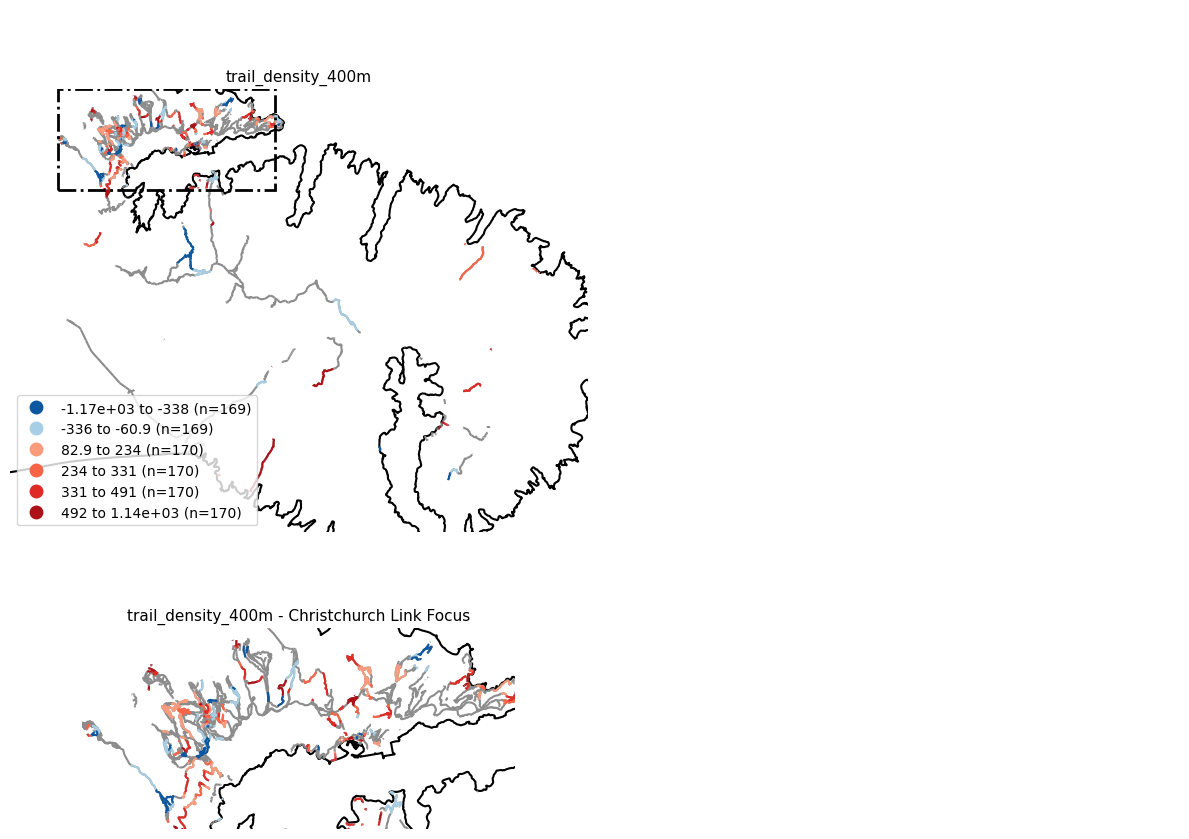

In [40]:
def plot_coefficient_grid(gdf, param_names, ncols=2, cmap="RdBu_r", markersize=8, crit_t=1.96, ngroups=6, focus_width_fraction=0.45, focus_height_fraction=0.16):
    from matplotlib.colors import ListedColormap
    from matplotlib.patches import Rectangle

    n = len(param_names)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        nrows * 2, ncols,
        figsize=(6 * ncols, 8.5 * nrows),
        gridspec_kw={"height_ratios": [3, 1] * nrows},
        facecolor="#ffffff",
    )
    axes = np.atleast_1d(axes).reshape(nrows * 2, ncols)

    min_x, min_y, max_x, max_y = gdf.total_bounds
    width = max_x - min_x
    height = max_y - min_y
    main_xlim = (min_x - 0.1 * width, max_x + 0.1 * width)
    main_ylim = (min_y - 0.1 * height, max_y)
    focus_xlim, focus_ylim = focus_area_bounds(
        gdf,
        x_start=CL_X_START,
        x_end=CL_X_END,
        y_start=CL_Y_START,
        y_end=CL_Y_END,
        padding=CL_PADDING,
    )

    for i, p in enumerate(param_names):
        row = (i // ncols) * 2
        col = i % ncols
        ax = axes[row, col]
        focus_ax = axes[row + 1, col]
        frame_colour = "#000000"
        b_col, se_col = f"b_{p}", f"se_{p}"
        t = gdf[b_col] / gdf[se_col]
        significant = t.abs() >= crit_t
        values = gdf.loc[significant, b_col].dropna().astype(float)

        def draw_parameter_map(target_ax, title, focused=False):
            plot_border_under(target_ax)
            gdf.plot(ax=target_ax, color="#8c8c8c", markersize=markersize, zorder=2)

            if len(values):
                grouped = pd.Series(np.nan, index=gdf.index, dtype=object)
                group_labels = []
                group_colours = []
                negative_count = int((values < 0).sum())
                positive_count = int((values > 0).sum())
                populated_signs = int(negative_count > 0) + int(positive_count > 0)
                total_groups = max(ngroups, populated_signs)

                if populated_signs == 2:
                    negative_groups = int(round(
                        total_groups * negative_count / (negative_count + positive_count)
                    ))
                    if p == "elevation_max":
                        negative_groups = max(1, negative_groups - 1)
                    negative_groups = min(max(negative_groups, 1), total_groups - 1)
                    groups_by_sign = {
                        -1: negative_groups,
                        1: total_groups - negative_groups,
                    }
                else:
                    groups_by_sign = {
                        -1: total_groups if negative_count else 0,
                        1: total_groups if positive_count else 0,
                    }

                for sign, cmap_name in ((-1, "Blues"), (1, "Reds")):
                    sign_values = values[values * sign > 0]
                    if not len(sign_values):
                        continue

                    n_sign_groups = min(groups_by_sign[sign], len(sign_values))
                    ranks = sign_values.rank(method="first")
                    sign_groups = pd.qcut(
                        ranks, q=n_sign_groups, labels=False
                    ).astype(int)

                    for group in range(n_sign_groups):
                        group_values = sign_values[sign_groups == group]
                        label = f"{group_values.min():.3g} to {group_values.max():.3g} (n={len(group_values)})"
                        group_labels.append(label)
                        grouped.loc[group_values.index] = label

                    colour_start, colour_end = (0.85, 0.35) if sign < 0 else (0.35, 0.85)
                    group_colours.extend(
                        plt.get_cmap(cmap_name)(
                            np.linspace(colour_start, colour_end, n_sign_groups)
                        )
                    )

                zero_values = values[values == 0]
                if len(zero_values):
                    zero_label = f"0 (n={len(zero_values)})"
                    group_labels.append(zero_label)
                    grouped.loc[zero_values.index] = zero_label
                    group_colours.append(plt.get_cmap("Greys")(0.55))

                grouped = pd.Categorical(
                    grouped, categories=group_labels, ordered=True
                )
                gdf.assign(_coefficient_group=grouped).plot(
                    column="_coefficient_group", ax=target_ax,
                    cmap=ListedColormap(group_colours), categorical=True,
                    markersize=markersize, legend=not focused,
                    legend_kwds={"loc": "lower left"} if not focused else None,
                    zorder=3,
                )

            if focused:
                target_ax.set_xlim(*focus_xlim)
                target_ax.set_ylim(*focus_ylim)
            else:
                target_ax.set_xlim(*main_xlim)
                target_ax.set_ylim(*main_ylim)
            target_ax.set_facecolor("#ffffff")
            target_ax.set_title(title, fontsize=11, color="black")
            target_ax.set_axis_off()

        draw_parameter_map(ax, p)
        draw_parameter_map(focus_ax, f"{p} - Christchurch Link Focus", focused=True)
        ax.add_patch(Rectangle(
            (focus_xlim[0], focus_ylim[0]),
            focus_xlim[1] - focus_xlim[0],
            focus_ylim[1] - focus_ylim[0],
            fill=False,
            edgecolor=frame_colour,
            linewidth=2,
            linestyle="-.",
            zorder=5,
        ))

    for i in range(n, nrows * ncols):
        row = (i // ncols) * 2
        col = i % ncols
        axes[row, col].set_facecolor("#ffffff")
        axes[row, col].set_axis_off()
        axes[row + 1, col].set_facecolor("#ffffff")
        axes[row + 1, col].set_axis_off()

    fig.tight_layout()
    return fig

fig1 = plot_coefficient_grid(gdf, param_names)
plt.show()


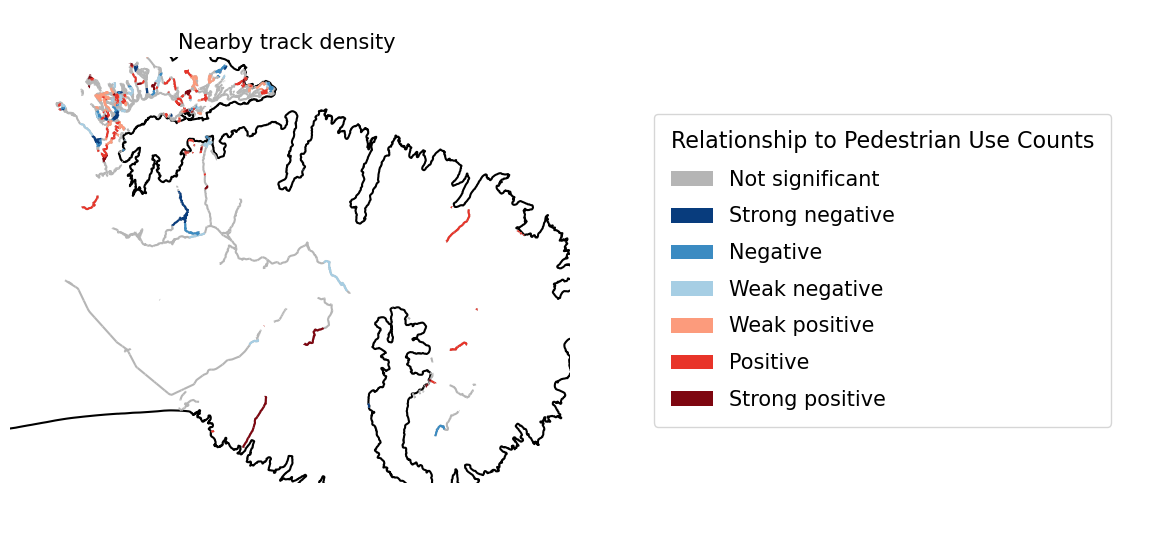

In [41]:
# Human-readable labels for the coefficient-map panes.
pane_labels = {
    "closeness_centrality": "Closeness to the wider track network ",
    "parking_distance": "Distance to parking ",
    "elevation_max": "Maximum elevation",
    "trail_density_400m": "Nearby track density ",
    "degree_centrality": "Number of directly connected tracks ",
}

class_labels = [
    "Strong negative",
    "Negative",
    "Weak negative",
    "Weak positive",
    "Positive",
    "Strong positive",
]
class_colours = [
    plt.get_cmap("Blues")(0.95),
    plt.get_cmap("Blues")(0.65),
    plt.get_cmap("Blues")(0.35),
    plt.get_cmap("Reds")(0.35),
    plt.get_cmap("Reds")(0.65),
    plt.get_cmap("Reds")(0.95),
]

n = len(param_names)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 5.5 * nrows),
    facecolor="#ffffff",
)

min_x, min_y, max_x, max_y = gdf.total_bounds
width = max_x - min_x
height = max_y - min_y
main_xlim = (min_x - 0.1 * width, max_x + 0.1 * width)
main_ylim = (min_y - 0.09 * height, max_y)

axes = np.atleast_1d(axes).ravel()

for i, parameter in enumerate(param_names):
    ax = axes[i]
    coefficient_column = f"b_{parameter}"
    standard_error_column = f"se_{parameter}"
    t_values = gdf[coefficient_column] / gdf[standard_error_column]
    significant = t_values.abs() >= 1.96
    values = gdf.loc[significant, coefficient_column].astype(float)

    grouped = pd.Series(np.nan, index=gdf.index, dtype=object)
    if len(values):
        negative_values = values[values < 0]
        positive_values = values[values > 0]

        if len(negative_values) and len(positive_values):
            negative_extent = abs(negative_values.min())
            positive_extent = positive_values.max()
            dominant_values = (
                negative_values
                if negative_extent >= positive_extent
                else positive_values
            )
        else:
            dominant_values = negative_values if len(negative_values) else positive_values

# Split the side with the larger range into three groups, then mirror
# the magnitude thresholds onto the opposite sign.
        split_values = abs(dominant_values.quantile([1 / 3, 2 / 3]).to_numpy())
        lower_split, upper_split = np.sort(split_values)

        grouped.loc[values.index[values <= -upper_split]] = "Strong negative"
        grouped.loc[values.index[(values > -upper_split) & (values <= -lower_split)]] = "Negative"
        grouped.loc[values.index[(values > -lower_split) & (values < 0)]] = "Weak negative"
        grouped.loc[values.index[(values >= 0) & (values < lower_split)]] = "Weak positive"
        grouped.loc[values.index[(values >= lower_split) & (values < upper_split)]] = "Positive"
        grouped.loc[values.index[values >= upper_split]] = "Strong positive"

    grouped = pd.Categorical(grouped, categories=class_labels, ordered=True)

    plot_border_under(ax)
    gdf.plot(ax=ax, color="#b5b5b5", markersize=8, zorder=2)
    gdf.assign(_coefficient_group=grouped).plot(
        column="_coefficient_group",
        ax=ax,
        cmap=ListedColormap(class_colours),
        categorical=True,
        markersize=8,
        legend=False,
        zorder=3,
    )
    ax.set_xlim(*main_xlim)
    ax.set_ylim(*main_ylim)
    ax.set_title(pane_labels.get(parameter, parameter), fontsize=15, color="black")
    ax.set_axis_off()

# Use the sixth pane for one shared legend instead of repeating it on every map.
for ax in axes[n:]:
    ax.set_facecolor("#ffffff")
    ax.set_axis_off()

if n < len(axes):
    legend_handles = [
        Patch(facecolor="#b5b5b5", edgecolor="none", label="Not significant"),
        *[
            Patch(facecolor=colour, edgecolor="none", label=label)
            for label, colour in zip(class_labels, class_colours)
        ],
    ]
    legend = axes[n].legend(
        handles=legend_handles,
        loc="center",
        title="Relationship to Pedestrian Use Counts",
        frameon=True,
        fontsize=15,
        title_fontsize=16,
        labelspacing=0.8,
        borderpad=0.8,
    )
    legend.set_alignment("left")

fig.tight_layout()
plt.show()


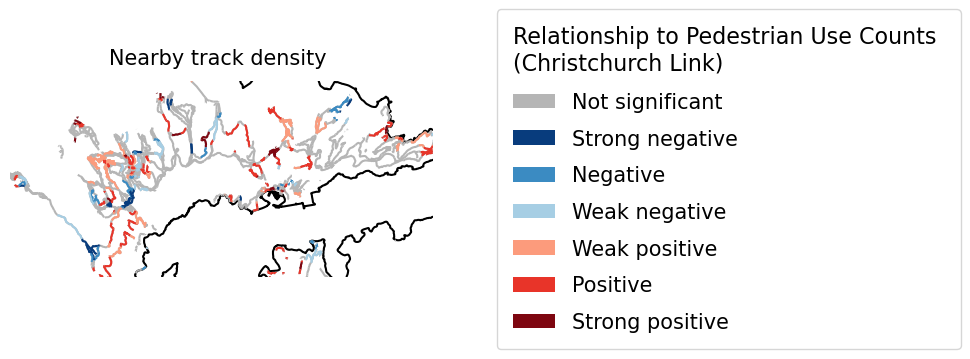

In [42]:
# focus version of the parameter estimate maps.
pane_labels = {
    "closeness_centrality": "Closeness to the wider track network ",
    "parking_distance": "Distance to parking ",
    "elevation_max": "Maximum elevation",
    "trail_density_400m": "Nearby track density ",
    "degree_centrality": "Number of directly connected tracks ",
}

class_labels = [
    "Strong negative",
    "Negative",
    "Weak negative",
    "Weak positive",
    "Positive",
    "Strong positive",
]
class_colours = [
    plt.get_cmap("Blues")(0.95),
    plt.get_cmap("Blues")(0.65),
    plt.get_cmap("Blues")(0.35),
    plt.get_cmap("Reds")(0.35),
    plt.get_cmap("Reds")(0.65),
    plt.get_cmap("Reds")(0.95),
]
focus_xlim, focus_ylim = focus_area_bounds(
    gdf,
    x_start=CL_X_START,
    x_end=CL_X_END,
    y_start=CL_Y_START,
    y_end=CL_Y_END,
    padding=CL_PADDING,
)

# focus_xlim, focus_ylim = focus_area_bounds(
#     gdf,
#     x_start=TAP_X_START,
#     x_end=TAP_X_END,
#     y_start=TAP_Y_START,
#     y_end=TAP_Y_END,
#     padding=TAP_PADDING,
# )

# focus_xlim, focus_ylim = focus_area_bounds(
#     gdf,
#     x_start=AKA_X_START,
#     x_end=AKA_X_END,
#     y_start=AKA_Y_START,
#     y_end=AKA_Y_END,
#     padding=AKA_PADDING,
# )

n = len(param_names)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 3.7 * nrows),
    facecolor="#ffffff",
)
axes = np.atleast_1d(axes).ravel()

for i, parameter in enumerate(param_names):
    ax = axes[i]
    coefficient_column = f"b_{parameter}"
    standard_error_column = f"se_{parameter}"
    t_values = gdf[coefficient_column] / gdf[standard_error_column]
    significant = t_values.abs() >= 1.96
    values = gdf.loc[significant, coefficient_column].astype(float)

    grouped = pd.Series(np.nan, index=gdf.index, dtype=object)
    if len(values):
        negative_values = values[values < 0]
        positive_values = values[values > 0]

        if len(negative_values) and len(positive_values):
            negative_extent = abs(negative_values.min())
            positive_extent = positive_values.max()
            dominant_values = (
                negative_values
                if negative_extent >= positive_extent
                else positive_values
            )
        else:
            dominant_values = negative_values if len(negative_values) else positive_values

        split_values = abs(dominant_values.quantile([1 / 3, 2 / 3]).to_numpy())
        lower_split, upper_split = np.sort(split_values)

        grouped.loc[values.index[values <= -upper_split]] = "Strong negative"
        grouped.loc[values.index[(values > -upper_split) & (values <= -lower_split)]] = "Negative"
        grouped.loc[values.index[(values > -lower_split) & (values < 0)]] = "Weak negative"
        grouped.loc[values.index[(values >= 0) & (values < lower_split)]] = "Weak positive"
        grouped.loc[values.index[(values >= lower_split) & (values < upper_split)]] = "Positive"
        grouped.loc[values.index[values >= upper_split]] = "Strong positive"

    grouped = pd.Categorical(grouped, categories=class_labels, ordered=True)

    plot_border_under(ax)
    gdf.plot(ax=ax, color="#b5b5b5", markersize=8, zorder=2)
    gdf.assign(_coefficient_group=grouped).plot(
        column="_coefficient_group",
        ax=ax,
        cmap=ListedColormap(class_colours),
        categorical=True,
        markersize=8,
        legend=False,
        zorder=3,
    )
    ax.set_xlim(*focus_xlim)
    ax.set_ylim(*focus_ylim)
    ax.set_title(pane_labels.get(parameter, parameter), fontsize=15, color="black", pad=12)
    ax.set_axis_off()

for ax in axes[n:]:
    ax.set_facecolor("#ffffff")
    ax.set_axis_off()

if n < len(axes):
    legend_handles = [
        Patch(facecolor="#b5b5b5", edgecolor="none", label="Not significant"),
        *[
            Patch(facecolor=colour, edgecolor="none", label=label)
            for label, colour in zip(class_labels, class_colours)
        ],
    ]
    legend = axes[n].legend(
        handles=legend_handles,
        loc="center",
        title="Relationship to Pedestrian Use Counts \n(Christchurch Link)",
        #title="Relationship to Pedestrian Use Counts \n(Te Ara Pa\u0304taka)",
        #title="Relationship to Pedestrian Use Counts \n(Akaroa)",
        frameon=True,
        fontsize=15,
        title_fontsize=16,
        labelspacing=0.8,
        borderpad=0.8,
    )
    legend.set_alignment("left")
    legend.get_title().set_position((0, 1.05))

#fig.subplots_adjust(hspace=0.08, wspace=0.12, left=0.02, right=0.98, top=0.98, bottom=0.02)
plt.show()


### Significance (pseudo t-values)

`t = b / se`. Values with `|t| < 1.96` are (approximately) not significant at the 95% level and are
shown hatched/greyed out on each map so the significant "hotspots" of each relationship stand out.


In [43]:
# def plot_tvalue_grid(gdf, param_names, ncols=3, cmap="RdBu_r", markersize=8, crit_t=1.96):
#     n = len(param_names)
#     nrows = int(np.ceil(n / ncols))
#     fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.5 * nrows))
#     axes = np.atleast_1d(axes).ravel()

#     for i, p in enumerate(param_names):
#         ax = axes[i]
#         b_col, se_col = f"b_{p}", f"se_{p}"
#         t = gdf[b_col] / gdf[se_col]
#         tmax = np.nanmax(np.abs(t))
#         norm = TwoSlopeNorm(vmin=-tmax, vcenter=0, vmax=tmax)

#         plot_border_under(ax)
#         gdf.assign(_t=t).plot(
#             column="_t", ax=ax, cmap=cmap, norm=norm,
#             markersize=markersize, legend=True,
#             legend_kwds={"shrink": 0.7, "label": "t-value"}, zorder=2,
#         )

#         not_sig = gdf[np.abs(t) < crit_t]
#         if len(not_sig):
#             not_sig.plot(ax=ax, color="lightgrey", markersize=markersize, alpha=0.6, zorder=3)

#         zoom_to_data(ax)
#         ax.set_title(f"{p}  (grey = |t| < {crit_t})", fontsize=10)
#         ax.set_axis_off()

#     for j in range(n, len(axes)):
#         axes[j].set_axis_off()

#     fig.suptitle("GWR pseudo t-values (significance)", fontsize=15, y=1.01)
#     fig.tight_layout()
#     return fig

# fig2 = plot_tvalue_grid(gdf, param_names)
# plt.show()


## 8. Local R-squared

Map the local goodness-of-fit statistic. If the fitted results do not expose `localR2` directly, the following cells use the notebook's fallback calculation based on adaptive neighbourhoods.

In [44]:
print("No 'localR2' found in the results object — falling back to a manual adaptive-neighbourhood "
        "approximation using the fitted bandwidth. Replace this with the real mgwr localR2 if you have it.")

bw = results["general_bandwidth"][0] if isinstance(results, dict) else results.bw
# Use centroids so this also works for polygon/line geometries, not just points.
# Centroids on a geographic (lat/lon) CRS are inaccurate for distance-based neighbour search,
# so reproject to the data's own projected CRS first if needed.
if gdf.crs is not None and gdf.crs.is_geographic:
    print(f"CRS {gdf.crs} is geographic — reprojecting to its UTM equivalent for centroid/distance calcs.")
    gdf_proj = gdf.to_crs(gdf.estimate_utm_crs())
else:
    gdf_proj = gdf
centroids = gdf_proj.geometry.centroid
coords = np.column_stack([centroids.x, centroids.y])
y = gdf["Y"].to_numpy(dtype=float)
yhat = gdf["yhat"].to_numpy(dtype=float)

tree = cKDTree(coords)
k = int(min(bw, len(gdf)))  # neighbourhood size capped to dataset size
_, idx = tree.query(coords, k=k)

local_r2 = np.empty(len(gdf))
for i in range(len(gdf)):
    nbrs = idx[i]
    y_local = y[nbrs]
    yhat_local = yhat[nbrs]
    ss_res = np.sum((y_local - yhat_local) ** 2)
    ss_tot = np.sum((y_local - y_local.mean()) ** 2)
    local_r2[i] = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
source = f"manual approximation (k={k} nearest neighbours)"

gdf["_local_r2"] = local_r2
print(f"Local R2 source: {source}")
print(gdf["_local_r2"].describe())


No 'localR2' found in the results object — falling back to a manual adaptive-neighbourhood approximation using the fitted bandwidth. Replace this with the real mgwr localR2 if you have it.
Local R2 source: manual approximation (k=42 nearest neighbours)
count    3126.000000
mean       -1.384965
std        25.720202
min     -1046.026960
25%         0.131692
50%         0.233569
75%         0.348450
max         0.909046
Name: _local_r2, dtype: float64


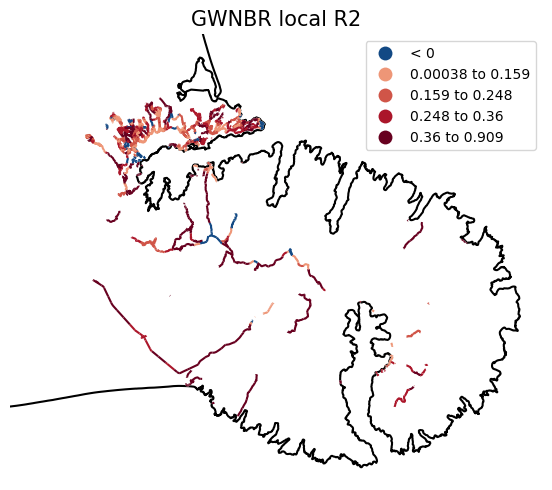

In [45]:
from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(10, 5), facecolor="#ffffff")
ax.set_facecolor("#ffffff")

local_r2_values = gdf["_local_r2"].astype(float)
non_negative = local_r2_values[local_r2_values >= 0].dropna()

grouped = pd.Series(np.nan, index=gdf.index, dtype=object)
grouped.loc[local_r2_values < 0] = "< 0"
positive_labels = []
if len(non_negative):
    positive_ranks = non_negative.rank(method="first")
    positive_groups = pd.qcut(positive_ranks, q=4, labels=False).astype(int)
    for group in range(4):
        group_values = non_negative[positive_groups == group]
        label = f"{group_values.min():.3g} to {group_values.max():.3g}"
        positive_labels.append(label)
        grouped.loc[group_values.index] = label

class_labels = ["< 0"] + positive_labels
grouped = pd.Categorical(grouped, categories=class_labels, ordered=True)

plot_border_under(ax)
gdf.plot(ax=ax, color="#ffffff", markersize=10, zorder=2)
redblue_cmap = plt.get_cmap("RdBu_r")
redblue_colors = np.vstack([
    redblue_cmap(0.05),
    redblue_cmap(np.linspace(0.72, 1.0, len(class_labels) - 1)),
])
gdf.assign(_local_r2_group=grouped).plot(
    column="_local_r2_group",
    ax=ax,
    cmap=ListedColormap(redblue_colors),
    categorical=True,
    markersize=10,
    legend=True,
    legend_kwds={"loc": "upper right"},
    zorder=3,
)
zoom_to_data(ax)

ax.set_title("GWNBR local R2", color="Black", fontsize=15)
ax.set_axis_off()
fig.tight_layout()
plt.show()

## 9. Standardised local GWR residuals

Map the standardised residuals from the local model. These show where observed counts differ from the locally fitted values after accounting for the model's spatially varying coefficients.

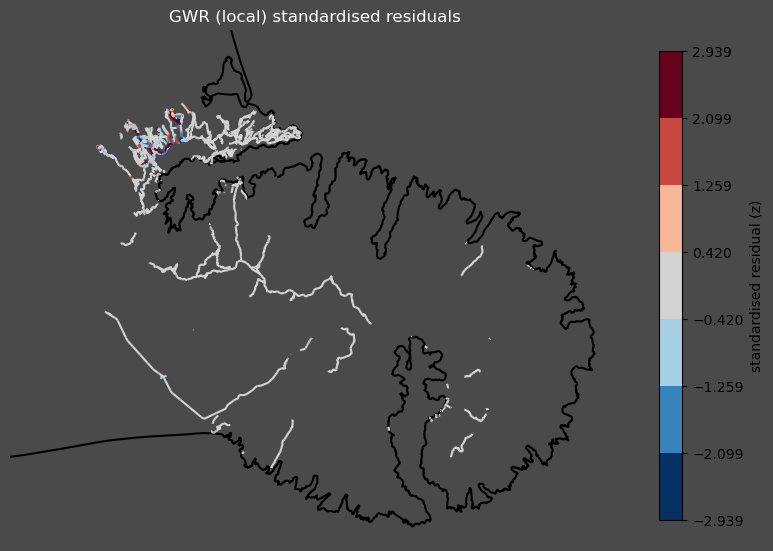

In [46]:
from matplotlib.colors import BoundaryNorm, ListedColormap

gdf["res_std"] = (gdf["res"] - gdf["res"].mean()) / gdf["res"].std()

fig, ax = plt.subplots(figsize=(8, 7), facecolor="#4a4a4a")
ax.set_facecolor("#4a4a4a")
vmax = np.nanmax(np.abs(gdf["res_std"]))/3
boundaries = np.linspace(-vmax, vmax, 8)
norm = BoundaryNorm(boundaries, ncolors=7, clip=True)
residual_colours = list(plt.get_cmap("RdBu_r")(np.linspace(0, 1, 7)))
residual_colours[3] = mpl.colors.to_rgba("lightgrey")
residual_cmap = ListedColormap(residual_colours)

plot_border_under(ax)
gdf.plot(
    column="res_std", ax=ax, cmap=residual_cmap, norm=norm,
    markersize=10, legend=True,
    legend_kwds={"shrink": 0.7, "label": "standardised residual (z)"},
    zorder=2,
 )
zoom_to_data(ax)
ax.set_title("GWR (local) standardised residuals", color="white")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 10. Standardised global negative-binomial residuals

Map residuals from the global negative-binomial model as a comparison benchmark. Contrasting these residuals with the local residuals helps show whether spatially varying coefficients improve the geographic pattern of model error.

In [47]:
import statsmodels.api as sm

# Fit a global negative-binomial model using the same predictors as the GWR.
global_predictors = [p for p in param_names if p.lower() not in ("alpha", "intercept")]
X = gdf[global_predictors].astype(float)
X = sm.add_constant(X)
y = gdf["Y"].astype(float)

global_theta = float(global_results["model_stats"]["theta"].iloc[0])
global_alpha = 1.0 / global_theta
global_model = sm.GLM(
    y, X, family=sm.families.NegativeBinomial(alpha=global_alpha)
).fit()
print(global_model.summary())
print(f"Global NB2 dispersion: theta={global_theta:.4f}, alpha={global_alpha:.4f}")

# Use the global negative-binomial fitted values for the residual comparison map.
gdf["yhat_global"] = global_model.predict(X)
gdf["res_global"] = gdf["Y"] - gdf["yhat_global"]
gdf["res_global_std"] = (gdf["res_global"] - gdf["res_global"].mean()) / gdf["res_global"].std()

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      Y   No. Observations:                 3126
Model:                            GLM   Df Residuals:                     3124
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -23645.
Date:                Fri, 06 Nov 2026   Deviance:                       6298.6
Time:                        01:30:53   Pearson chi2:                 8.93e+03
No. Iterations:                    11   Pseudo R-squ. (CS):            0.07317
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  6.6087      0

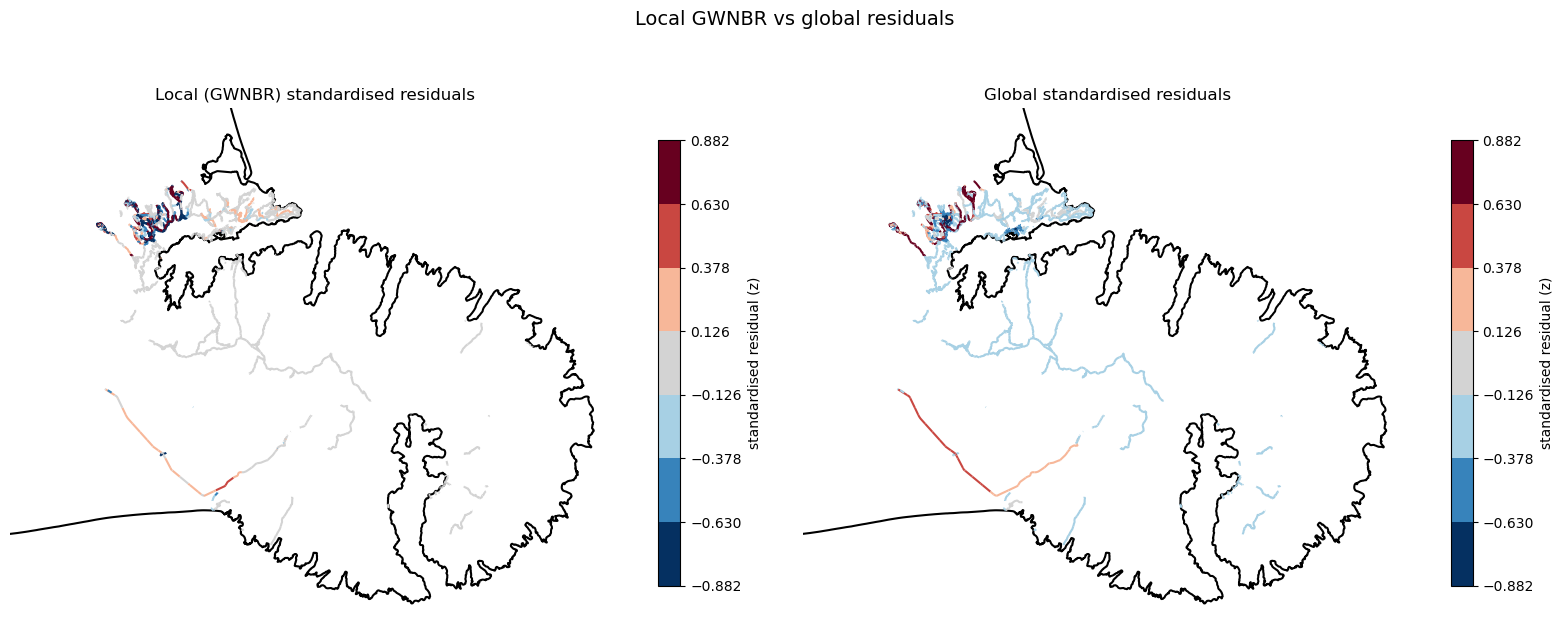

In [48]:
from matplotlib.colors import BoundaryNorm, ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor="#ffffff")

vmax = max(
    np.nanmax(np.abs(gdf["res_std"])),
    np.nanmax(np.abs(gdf["res_global_std"])),
 )/10
boundaries = np.linspace(-vmax, vmax, 8)
norm = BoundaryNorm(boundaries, ncolors=7, clip=True)
residual_colours = list(plt.get_cmap("RdBu_r")(np.linspace(0, 1, 7)))
residual_colours[3] = mpl.colors.to_rgba("lightgrey")
residual_cmap = ListedColormap(residual_colours)

for ax in axes:
    ax.set_facecolor("#4a4a4a")

plot_border_under(axes[0])
gdf.plot(column="res_std", ax=axes[0], cmap=residual_cmap, norm=norm, markersize=10,
         legend=True, legend_kwds={"shrink": 0.7, "label": "standardised residual (z)"}, zorder=2)
zoom_to_data(axes[0])
axes[0].set_title("Local (GWNBR) standardised residuals", color="black")
axes[0].set_axis_off()

plot_border_under(axes[1])
gdf.plot(column="res_global_std", ax=axes[1], cmap=residual_cmap, norm=norm, markersize=10,
         legend=True, legend_kwds={"shrink": 0.7, "label": "standardised residual (z)"}, zorder=2)
zoom_to_data(axes[1])
axes[1].set_title("Global standardised residuals", color="black")
axes[1].set_axis_off()

fig.suptitle("Local GWNBR vs global residuals", fontsize=14, color="black")
fig.tight_layout()
plt.show()


## 11. Model-fit summary

Extract headline diagnostics from the local and global results, including deviance, log-likelihood, pseudo-R-squared, AIC, AICc, effective number of parameters (`ENP`), and fitted bandwidth, for side-by-side comparison.

In [49]:
def measures_to_series(measures_da):
    return pd.Series(np.asarray(measures_da), index=[str(x) for x in measures_da['dim_0'].values])

if isinstance(results, dict):
    bw = results.get("general_bandwidth")
    print("Bandwidth:", bw)

    if "measures" in results and "global_model" in globals():
        gwr_measures = measures_to_series(results["measures"])
        aic_comparison = pd.DataFrame({
            "Model": ["GWR", "Global negative binomial"],
            "AIC": [gwr_measures.get("AIC", np.nan), global_model.aic],
        }).set_index("Model")
        print("\nAIC comparison:")
        display(aic_comparison)

    #if "ENP" in results:
    #    enp = measures_to_series(results["ENP"]) if hasattr(results["ENP"], "coords") else pd.Series(results["ENP"])
    #    print("\nEffective number of parameters per term:")
    #    display(enp)


Bandwidth: [42.]

AIC comparison:


,AIC
Model,
GWR,42985.720144
Global negative binomial,47293.099020


In [50]:
global_coef = global_results["coef_table"].copy()
gwr_terms = [
    column[2:]
    for column in gdf.columns
    if column.startswith("b_") and column not in EXCLUDE_FROM_COEF_PLOTS
]
excluded_global_terms = [
    term for term in global_coef["term"]
    if term not in gwr_terms and term not in ("(Intercept)", "Intercept", "alpha")
]
if excluded_global_terms:
    print("Global terms without matching GWR local estimates:", excluded_global_terms)

rows = []
for _, global_row in global_coef.iterrows():
    term = str(global_row["term"])
    if term in ("(Intercept)", "Intercept", "alpha") or term not in gwr_terms:
        continue

    local_values = gdf[f"b_{term}"].astype(float)
    significance = "*" if float(global_row["p.value"]) < 0.05 else ""
    rows.append({
        "Variable": term,
        "Global regression b": float(global_row["estimate"]),
        "Global t-value": f"{float(global_row['statistic']):.3f}{significance}",
        "GWR b(i) Min": local_values.min(),
        "GWR b(i) Max": local_values.max(),
        "GWR b(i) Mean": local_values.mean(),
        "GWR b(i) StDev": local_values.std(),
    })

parameter_comparison = pd.DataFrame(rows).set_index("Variable")
display(parameter_comparison.style.format({
    "Global regression b": "{:.4g}",
    "GWR b(i) Min": "{:.4g}",
    "GWR b(i) Max": "{:.4g}",
    "GWR b(i) Mean": "{:.4g}",
    "GWR b(i) StDev": "{:.4g}",
}))

Global terms without matching GWR local estimates: ['closeness_centrality', 'parking_distance', 'elevation_max', 'degree_centrality', 'elevation_range']


,Global regression b,Global t-value,GWR b(i) Min,GWR b(i) Max,GWR b(i) Mean,GWR b(i) StDev
Variable,,,,,,
trail_density_400m,-20.73,-14.870*,-1198,1136,46.7,289
